# Degradation as Biomarker or Shortcut? — Fundus Arm (MIDL 2027)
**APTOS-2019 (train/val/test) + Messidor-2 (external OOD)**. Runs end-to-end on one Kaggle T4.

**Before running:** enable *Internet* (Settings → Internet → On) so `pyiqa` can install. Add both datasets: `APTOS-2019 dataset` and `messidor-2`. Runtime → Run All.

Pipeline: (1) auto path/CSV discovery → (2) degradation feature extraction (pyiqa IQA + handcrafted, cached CSV) → (3) probe study + negative control → (4) 4 model arms (baseline / harness / suppress-GRL / augmentation) → (5) evaluation: AUC + bootstrap CI, ECE, quality-tercile AUC, domain & degradation probes, t-SNE. Outputs land in `/kaggle/working/results/` for download into the paper.

In [1]:
!pip install -q pyiqa timm

import os, sys, glob, json, time, random, warnings, fnmatch, math
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as T
from PIL import Image, ImageEnhance, ImageFilter
from scipy import ndimage
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.manifold import TSNE
from sklearn.metrics import roc_auc_score, accuracy_score, cohen_kappa_score

warnings.filterwarnings('ignore')
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.backends.cudnn.benchmark = True
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
WORK = '/kaggle/working'
for d in ['features', 'ckpt', 'results']:
    os.makedirs(f'{WORK}/{d}', exist_ok=True)
INPUT = '/kaggle/input'
print('device:', DEVICE)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 36.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.8/46.8 kB 2.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 178.0/178.0 kB 8.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.0/41.0 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 89.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 48.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.6/59.6 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 226.2/226.2 kB 11.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 103.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 256.2/256.2 kB 10.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.5/99.5 kB 5.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 

## 1. Auto path & CSV discovery
Walks `/kaggle/input`, locates the APTOS image folders and CSVs and the Messidor-2 CSV, then auto-detects id and label columns with a candidate list + numeric heuristics. Everything it detects is printed; if a label column is ambiguous it stops with a clear message — paste that printout for help.

In [2]:
def walk_input():
    for root, dirs, files in os.walk(INPUT):
        yield root, dirs, files

def find_dirs(patterns):
    hits = []
    for root, dirs, _ in walk_input():
        for d in dirs:
            if any(fnmatch.fnmatch(d.lower(), p) for p in patterns):
                hits.append(os.path.join(root, d))
    return hits

def find_files(patterns, under=None):
    hits = []
    for root, _, files in walk_input():
        if under and not root.startswith(under):
            continue
        for f in files:
            if any(fnmatch.fnmatch(f.lower(), p) for p in patterns):
                hits.append(os.path.join(root, f))
    return hits

train_dirs = find_dirs(['train*'])
val_dirs   = [d for d in find_dirs(['val*', 'valid*']) if 'train' not in os.path.basename(d).lower()]
test_dirs  = [d for d in find_dirs(['test*']) if 'train' not in os.path.basename(d).lower()]
mess_root  = [d for d in find_dirs(['messidor*'])
              if os.path.exists(os.path.join(d, 'messidor_data.csv'))]
assert train_dirs and mess_root, 'Could not locate APTOS train_images or messidor_data.csv - check dataset names.'

mess_img_root = os.path.dirname(mess_root[0])
all_csvs   = find_files(['*.csv'])
aptos_csvs = [c for c in all_csvs if 'messidor' not in c.lower().replace('_', '')]
print('train_dirs :', train_dirs)
print('val_dirs   :', val_dirs)
print('test_dirs  :', test_dirs)
print('messidor   :', mess_root)
print('aptos csvs :', aptos_csvs)

IMG_EXT = ('.png', '.jpg', '.jpeg', '.tif', '.tiff')

def norm_id(v):
    """basename -> lowercase -> strip extension -> keep alphanumerics only."""
    v = os.path.basename(str(v).strip()).lower()
    v = os.path.splitext(v)[0]
    return ''.join(ch for ch in v if ch.isalnum())

def id2path_map(dirs):
    m = {}
    for d in dirs:
        for p in glob.glob(os.path.join(d, '**', '*.*'), recursive=True):
            if p.lower().endswith(IMG_EXT):
                m[norm_id(p)] = p
    return m

def pick_id_col(df, idmap):
    """Choose the column whose values actually match image filenames."""
    keys = set(idmap.keys())
    best_c, best_s = None, 0.0
    for c in df.columns:
        vals = df[c].astype(str).map(norm_id)
        s = float(vals.isin(keys).mean())
        if s > best_s:
            best_c, best_s = c, s
    return best_c, best_s

train_map = id2path_map(train_dirs)
val_map   = id2path_map(val_dirs)
test_map  = id2path_map(test_dirs)
mess_map  = {norm_id(p): p for p in glob.glob(os.path.join(mess_img_root, '**', '*.*'), recursive=True)
             if p.lower().endswith(IMG_EXT)}
print('images: aptos train/val/test =', len(train_map), len(val_map), len(test_map), '| messidor =', len(mess_map))

def norm(s): return str(s).strip().lower().replace('_', '').replace(' ', '').replace('-', '')
LAB_CANDS = [norm(c) for c in ['diagnosis', 'adjudicated_dr_grade', 'retinopathy_grade', 'dr_grade',
                               'diabetic_retinopathy', 'level', 'label', 'grade', 'dr', 'target']]

def pick_label_col(df):
    # prefer a name-match whose values look like a 0-4 grade
    for c in df.columns:
        if norm(c) in LAB_CANDS and pd.api.types.is_numeric_dtype(df[c]):
            vals = pd.to_numeric(df[c], errors='coerce').dropna().unique()
            if len(vals) and vals.min() >= 0 and vals.max() <= 4:
                return c
    # fallback: few-unique numeric column (flagged loudly)
    best, bs = None, 1e9
    for c in df.columns:
        if pd.api.types.is_numeric_dtype(df[c]):
            u = df[c].dropna().unique()
            if 1 < len(u) <= 10 and len(u) < bs:
                best, bs = c, len(u)
    if best is not None:
        print(f'  WARNING: label column "{best}" chosen by heuristic, verify it is the DR grade.')
    return best

def load_csv(path):
    for sep in [',', ';', '\t']:
        try:
            return pd.read_csv(path, sep=sep)
        except Exception:
            continue
    raise ValueError(f'cannot read {path}')

def build_frame(csv_path, idmap, source):
    df = load_csv(csv_path)
    idc, rate = pick_id_col(df, idmap)
    print(f'[{source}] csv={os.path.basename(csv_path)} cols={list(df.columns)}')
    print(f'[{source}] id column="{idc}" (filename match rate={rate:.1%})')
    if rate < 0.9 and idc is not None:
        vals = df[idc].astype(str).map(norm_id)
        print(f'  sample unmatched ids :', vals[~vals.isin(set(idmap))].head(5).tolist())
        print(f'  sample image keys    :', list(idmap)[:5])
    assert idc is not None and rate > 0.5, \
        f'[{source}] could not match CSV ids to image files - see samples above and report them.'
    lab = pick_label_col(df)
    print(f'[{source}] label column="{lab}"')
    assert lab is not None, f'[{source}] no label column found - extend LAB_CANDS manually.'
    out = pd.DataFrame({'id': df[idc].astype(str).map(norm_id),
                        'grade': pd.to_numeric(df[lab], errors='coerce')})
    out['path'] = out['id'].map(idmap)
    out = out.dropna(subset=['path', 'grade'])
    out['source'] = source
    out['label'] = (out['grade'] >= 2).astype(int)  # referable DR (moderate+)
    return out.reset_index(drop=True)

def find_csv(names):
    for n in names:
        for p in aptos_csvs:
            if os.path.basename(p).lower() == n:
                return p
    return None

tr = build_frame(find_csv(['train_1.csv', 'train.csv']), train_map, 'aptos_train')
va = build_frame(find_csv(['valid.csv', 'val.csv']), val_map, 'aptos_val') if val_map else None
te = build_frame(find_csv(['test.csv']), test_map, 'aptos_test') if test_map else None

# messidor
mdf = load_csv(os.path.join(mess_root[0], 'messidor_data.csv'))
midc, mrate = pick_id_col(mdf, mess_map)
print(f'[messidor] cols={list(mdf.columns)}')
print(f'[messidor] id column="{midc}" (filename match rate={mrate:.1%})')
if mrate < 0.9 and midc is not None:
    vals = mdf[midc].astype(str).map(norm_id)
    print('  sample unmatched ids :', vals[~vals.isin(set(mess_map))].head(5).tolist())
    print('  sample image keys    :', list(mess_map)[:5])
assert midc is not None and mrate > 0.5, \
    'messidor: could not match CSV ids to image files - see samples above and report them.'
mlab = pick_label_col(mdf)
print(f'[messidor] label column="{mlab}"')
assert mlab is not None, 'messidor: no label column found - extend LAB_CANDS manually.'
me = pd.DataFrame({'id': mdf[midc].astype(str).map(norm_id),
                   'grade': pd.to_numeric(mdf[mlab], errors='coerce')})
me['path'] = me['id'].map(mess_map)
me = me.dropna(subset=['path', 'grade'])
me['source'] = 'messidor'
me['label'] = (me['grade'] >= 2).astype(int)

# de-duplicate val/test against train to prevent leakage
if va is not None:
    va = va[~va['id'].isin(set(tr['id']))]
if te is not None:
    te = te[~te['id'].isin(set(tr['id']))]

# if val empty/missing, carve stratified 15% from train
if va is None or len(va) < 50:
    va = tr.groupby('label', group_keys=False).apply(
        lambda x: x.sample(frac=0.15, random_state=SEED)).reset_index(drop=True)
    tr = tr[~tr['id'].isin(set(va['id']))].reset_index(drop=True)

for name, d in [('train', tr), ('val', va), ('test', te), ('messidor', me)]:
    if d is not None and len(d):
        print(f'{name:9s} n={len(d):5d}  pos_rate={d.label.mean():.3f}  grades={sorted(d.grade.unique())}')
assert len(me) > 0, 'messidor frame is empty after matching - see match-rate printout above.'
if te is None or len(te) < 50:
    print('NOTE: no usable APTOS test labels -> internal test = val set (report as such in the paper).')
    te = va
all_df = pd.concat([tr, va, te, me], ignore_index=True)
all_df.to_csv(f'{WORK}/features/frames.csv', index=False)
print('TOTAL images:', len(all_df))

train_dirs : ['/kaggle/input/datasets/mariaherrerot/aptos2019/train_images', '/kaggle/input/datasets/mariaherrerot/aptos2019/train_images/train_images']
val_dirs   : ['/kaggle/input/datasets/mariaherrerot/aptos2019/val_images', '/kaggle/input/datasets/mariaherrerot/aptos2019/val_images/val_images']
test_dirs  : ['/kaggle/input/datasets/mariaherrerot/aptos2019/test_images', '/kaggle/input/datasets/mariaherrerot/aptos2019/test_images/test_images']
messidor   : ['/kaggle/input/datasets/xyaustin/messidor2/messidor-2']
aptos csvs : ['/kaggle/input/datasets/mariaherrerot/aptos2019/valid.csv', '/kaggle/input/datasets/mariaherrerot/aptos2019/test.csv', '/kaggle/input/datasets/mariaherrerot/aptos2019/train_1.csv']
images: aptos train/val/test = 2930 366 366 | messidor = 1748
[aptos_train] csv=train_1.csv cols=['id_code', 'diagnosis']
[aptos_train] id column="id_code" (filename match rate=100.0%)
[aptos_train] label column="diagnosis"
[aptos_val] csv=valid.csv cols=['id_code', 'diagnosis']
[apto

## 2. Degradation feature extraction
No-reference IQA (BRISQUE, NIQE, PIQE, MUSIQ via pyiqa, GPU-batched) + handcrafted physical features (Laplacian blur, luminance, colorfulness, dark-channel prior, RMS contrast, dynamic range). Cached to CSV — re-runs are free.

In [3]:
import pyiqa

FEATS = ['brisque', 'niqe', 'piqe', 'musiq', 'blur', 'lum_mean', 'lum_std', 'colorfulness',
         'dark_channel', 'rms_contrast', 'dyn_range']

class DegradationExtractor:
    def __init__(self, device):
        self.device = device
        self.iqa = {m: pyiqa.create_metric(m, device=device)
                    for m in ['brisque', 'niqe', 'piqe', 'musiq']}
    @staticmethod
    def _t(img, size=512):
        img = img.convert('RGB').resize((size, size), Image.BICUBIC)
        return torch.from_numpy(np.asarray(img)).permute(2, 0, 1).float() / 255.
    def handcrafted(self, img):
        a = np.asarray(img.convert('RGB').resize((256, 256), Image.BICUBIC)).astype(np.float32) / 255.
        g = a.mean(axis=2)
        blur = float(ndimage.laplace(g).var())
        r, gg, b = a[..., 0], a[..., 1], a[..., 2]
        rg, yb = r - gg, 0.5 * (r + gg) - b
        colorfulness = float(np.sqrt(rg.std()**2 + yb.std()**2) + 0.3*np.sqrt(rg.mean()**2 + yb.mean()**2))
        sw = np.lib.stride_tricks.sliding_window_view(g, (15, 15))
        dark = float(sw.min(axis=(-1, -2)).mean())
        return dict(blur=blur, lum_mean=float(g.mean()), lum_std=float(g.std()),
                    colorfulness=colorfulness, dark_channel=dark,
                    rms_contrast=float(g.std()),
                    dyn_range=float(np.percentile(g, 99) - np.percentile(g, 1)))
    @torch.no_grad()
    def extract(self, df, batch=16):
        rows, paths = [], df['path'].tolist()
        for i in range(0, len(paths), batch):
            chunk = paths[i:i + batch]
            imgs = [Image.open(p) for p in chunk]
            t = torch.stack([self._t(im) for im in imgs]).to(self.device)
            sc = {m: self.iqa[m](t).flatten().cpu().numpy() for m in self.iqa}
            for j, im in enumerate(imgs):
                row = {m: float(sc[m][j]) for m in sc}
                row.update(self.handcrafted(im))
                rows.append(row)
            if (i // batch) % 25 == 0:
                print(f'  {min(i + batch, len(paths))}/{len(paths)}', end='\r')
        out = df[['id', 'source', 'label', 'grade', 'path']].reset_index(drop=True).copy()
        return pd.concat([out, pd.DataFrame(rows)], axis=1)

ext = DegradationExtractor(DEVICE)
feat_frames = []
for name, d in [('train', tr), ('val', va), ('test', te), ('messidor', me)]:
    cache = f'{WORK}/features/{name}_degradation.csv'
    if os.path.exists(cache):
        f = pd.read_csv(cache)
        ok = len(f) == len(d) and set(['id', 'source', 'label', 'grade', 'path']).issubset(f.columns)
        if ok and f['label'].isna().any():
            ok = False
        if ok:
            print(f'{name}: loaded cache ({len(f)} rows)')
        else:
            print(f'{name}: STALE/INVALID cache (rows={len(f)} vs expected {len(d)}) -> re-extracting')
            f = ext.extract(d)
            f.to_csv(cache, index=False)
    else:
        print(f'{name}: extracting {len(d)} images...')
        f = ext.extract(d)
        f.to_csv(cache, index=False)
    feat_frames.append(f)
F = pd.concat(feat_frames, ignore_index=True)
F.to_csv(f'{WORK}/features/all_degradation.csv', index=False)
print('features done:', F.shape)

Downloading: "https://huggingface.co/chaofengc/IQA-PyTorch-Weights/resolve/main/brisque_svm_weights.pth" to /root/.cache/torch/hub/pyiqa/brisque_svm_weights.pth



100%|██████████| 112k/112k [00:00<00:00, 468kB/s]


Downloading: "https://huggingface.co/chaofengc/IQA-PyTorch-Weights/resolve/main/niqe_modelparameters.mat" to /root/.cache/torch/hub/pyiqa/niqe_modelparameters.mat



100%|██████████| 8.15k/8.15k [00:00<00:00, 13.4MB/s]


Downloading: "https://huggingface.co/chaofengc/IQA-PyTorch-Weights/resolve/main/musiq_koniq_ckpt-e95806b9.pth" to /root/.cache/torch/hub/pyiqa/musiq_koniq_ckpt-e95806b9.pth



100%|██████████| 104M/104M [00:04<00:00, 24.2MB/s]


Loading pretrained model MUSIQ from /root/.cache/torch/hub/pyiqa/musiq_koniq_ckpt-e95806b9.pth
train: extracting 2930 images...
val: extracting 366 images...
test: extracting 366 images...
messidor: extracting 1744 images...
features done: (5406, 16)


## 3. Figure 1 — degradation distributions by source + clean vs. hazy examples

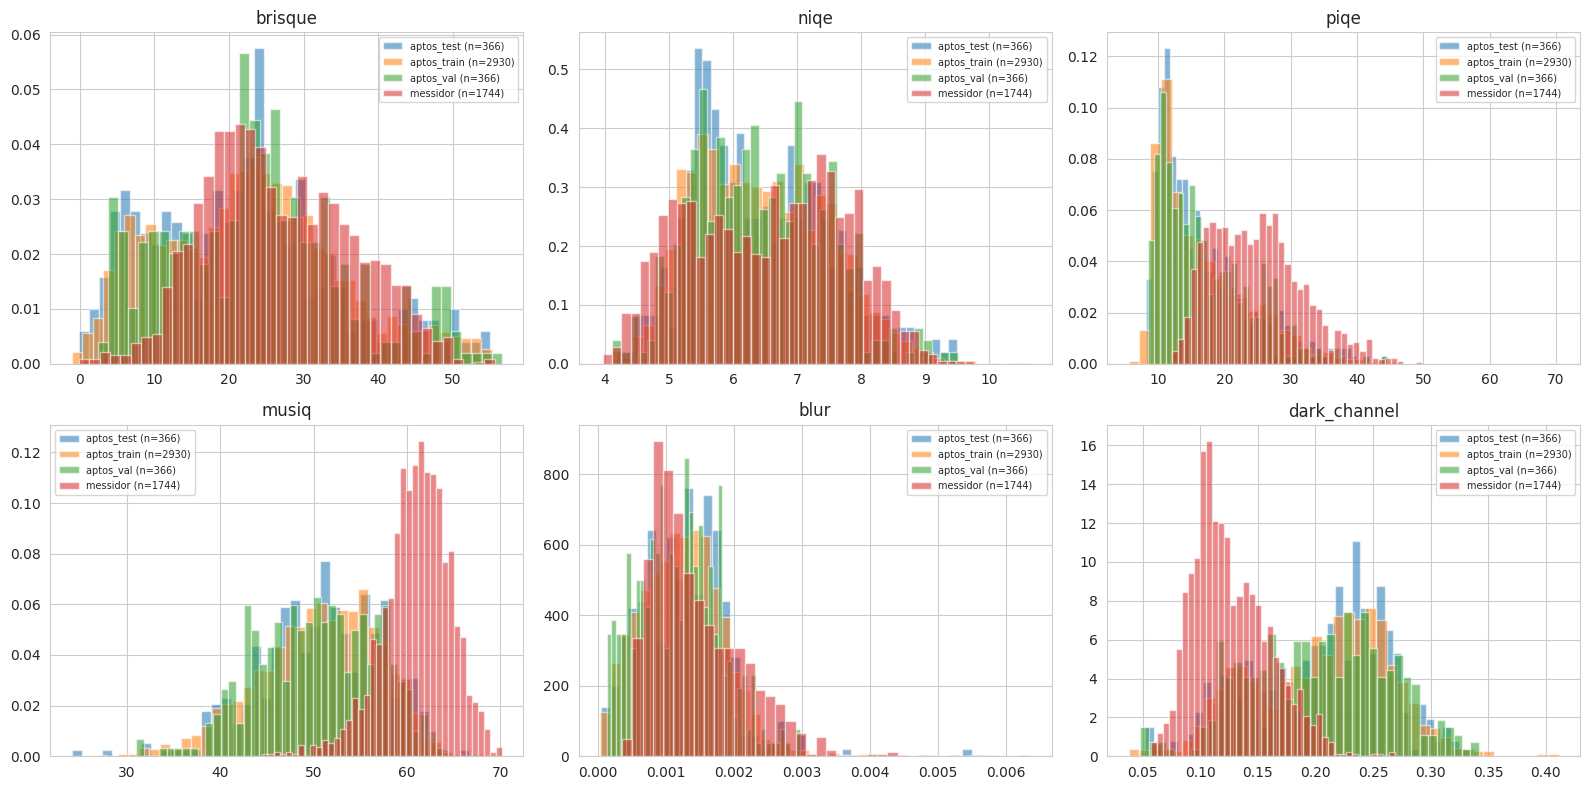

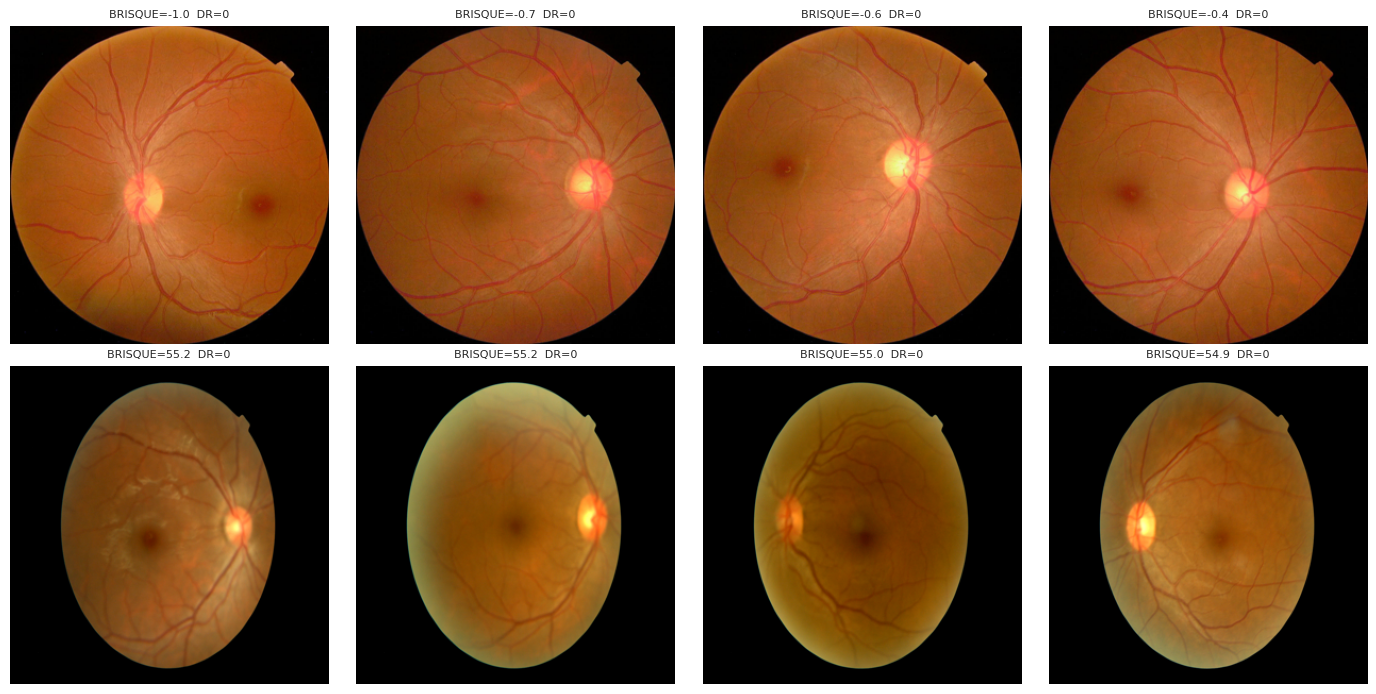

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style('whitegrid')

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, ft in zip(axes.ravel(), ['brisque', 'niqe', 'piqe', 'musiq', 'blur', 'dark_channel']):
    for src, d in F.groupby('source'):
        ax.hist(d[ft], bins=40, alpha=0.55, label=f'{src} (n={len(d)})', density=True)
    ax.set_title(ft); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(f'{WORK}/results/fig1_degradation_distributions.png', dpi=200); plt.show()

tr_f = F[F.source == 'aptos_train']
ex = pd.concat([tr_f.nsmallest(4, 'brisque'), tr_f.nlargest(4, 'brisque')])
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, (_, r) in zip(axes.ravel(), ex.iterrows()):
    ax.imshow(Image.open(r['path']).resize((300, 300))); ax.axis('off')
    ax.set_title(f"BRISQUE={r['brisque']:.1f}  DR={int(r['grade'])}", fontsize=8)
plt.tight_layout(); plt.savefig(f'{WORK}/results/fig1b_clean_vs_hazy.png', dpi=200); plt.show()

## 4. Probe study (RQ1) — is disease predictable from degradation alone?
5-fold CV on APTOS train (logistic + gradient boosting), negative control with shuffled features, external transfer to Messidor-2, prevalence-by-degradation-bin curves (core paper figure), and a 5-grade ordinal probe with quadratic-weighted kappa.

=== probe diagnostics ===
F shape: (5406, 16)
F source counts: {'aptos_train': 2930, 'messidor': 1744, 'aptos_val': 366, 'aptos_test': 366}
label dtype: int64 | NaN labels: 0
tr_mask rows: 2930 | me_mask rows: 1744
                                        probe           value
                    APTOS 5-fold AUC - LogReg 0.903 +/- 0.006
                       APTOS 5-fold AUC - GBM 0.945 +/- 0.003
        APTOS 5-fold AUC - SHUFFLED (control) 0.494 +/- 0.006
Messidor external AUC (from degradation only)           0.659
                   Messidor 5-grade QWK (GBM)           0.167


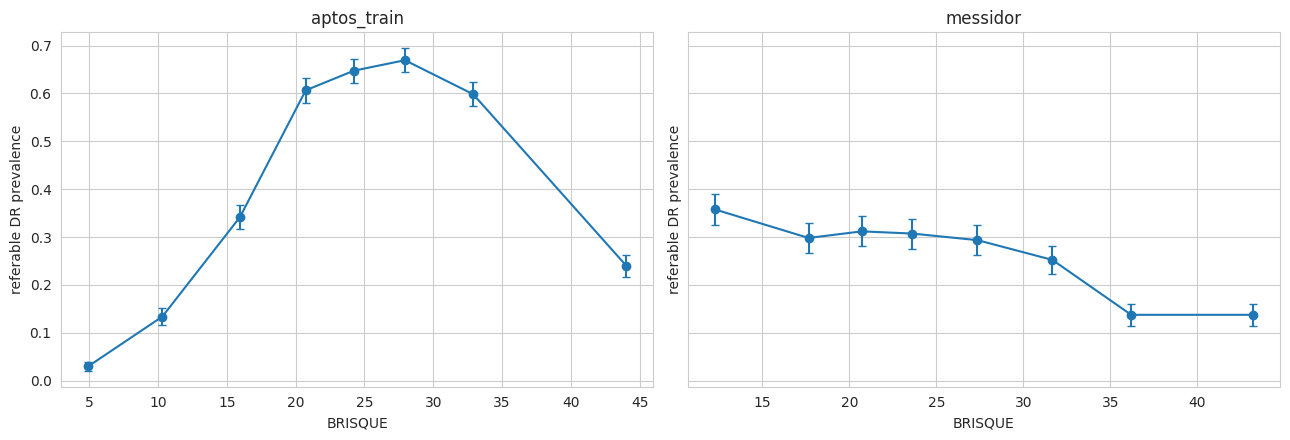

In [5]:
print('=== probe diagnostics ===')
print('F shape:', F.shape)
print('F source counts:', F.source.value_counts().to_dict())
print('label dtype:', F.label.dtype, '| NaN labels:', int(F.label.isna().sum()))
tr_mask = (F.source.values == 'aptos_train')
me_mask = (F.source.values == 'messidor')
print('tr_mask rows:', int(tr_mask.sum()), '| me_mask rows:', int(me_mask.sum()))
assert tr_mask.sum() > 100, ('F has no/few aptos_train rows - almost certainly a stale features cache from the '
                             'earlier failed run. Fix: restart the kernel, run  !rm -f /kaggle/working/features/*.csv  '
                             'then Run All.')
assert me_mask.sum() > 100, 'F has no messidor rows - check Section 1 match-rate printout.'
assert not np.isnan(F.label.values[tr_mask]).any(), 'NaN labels in aptos_train rows of F.'
ytr = F.label.values[tr_mask].astype(int)
gtr = F.grade.values[tr_mask].astype(int)

mu, sd = F.loc[F.source == 'aptos_train', FEATS].mean(), F.loc[F.source == 'aptos_train', FEATS].std().replace(0, 1)
X = ((F[FEATS] - mu) / sd).values
assert not np.isnan(X).any(), 'NaN in feature matrix X - inspect feature extraction.'

def cv_auc(Xm, y, model_fn, n_splits=5):
    skf = StratifiedKFold(n_splits, shuffle=True, random_state=SEED)
    aucs = []
    for tr_i, va_i in skf.split(Xm, y):
        m = model_fn(); m.fit(Xm[tr_i], y[tr_i])
        aucs.append(roc_auc_score(y[va_i], m.predict_proba(Xm[va_i])[:, 1]))
    return float(np.mean(aucs)), float(np.std(aucs))

probe_lr = cv_auc(X[tr_mask], ytr, lambda: LogisticRegression(max_iter=3000))
probe_gb = cv_auc(X[tr_mask], ytr, lambda: HistGradientBoostingClassifier(max_iter=300, random_state=SEED))

rng = np.random.default_rng(0)
Xsh = X.copy()
for j in range(Xsh.shape[1]):
    Xsh[:, j] = Xsh[rng.permutation(len(Xsh)), j]
shuf_lr = cv_auc(Xsh[tr_mask], ytr, lambda: LogisticRegression(max_iter=3000))

mm = LogisticRegression(max_iter=3000).fit(X[tr_mask], ytr)
ext_auc = roc_auc_score(F.label.values[me_mask], mm.predict_proba(X[me_mask])[:, 1])

gb5 = HistGradientBoostingClassifier(max_iter=300, random_state=SEED).fit(X[tr_mask], gtr)
qwk = cohen_kappa_score(F.grade.values[me_mask], gb5.predict(X[me_mask]), weights='quadratic')

probe_tbl = pd.DataFrame({
    'probe': ['APTOS 5-fold AUC - LogReg', 'APTOS 5-fold AUC - GBM', 'APTOS 5-fold AUC - SHUFFLED (control)',
              'Messidor external AUC (from degradation only)', 'Messidor 5-grade QWK (GBM)'],
    'value': [f'{probe_lr[0]:.3f} +/- {probe_lr[1]:.3f}', f'{probe_gb[0]:.3f} +/- {probe_gb[1]:.3f}',
              f'{shuf_lr[0]:.3f} +/- {shuf_lr[1]:.3f}', f'{ext_auc:.3f}', f'{qwk:.3f}']})
print(probe_tbl.to_string(index=False))
probe_tbl.to_csv(f'{WORK}/results/table1_probe.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, src in zip(axes, ['aptos_train', 'messidor']):
    d = F[F.source == src].copy()
    d['bin'] = pd.qcut(d['brisque'], 8, duplicates='drop')
    g = d.groupby('bin', observed=True).agg(prev=('label', 'mean'), n=('label', 'size'), brisque=('brisque', 'mean'))
    ax.errorbar(g['brisque'], g['prev'], yerr=np.sqrt(g['prev'] * (1 - g['prev']) / g['n']), marker='o', capsize=3)
    ax.set_title(src); ax.set_xlabel('BRISQUE'); ax.set_ylabel('referable DR prevalence')
plt.tight_layout(); plt.savefig(f'{WORK}/results/fig2_prevalence_vs_degradation.png', dpi=200); plt.show()

## 5. Models — 4 arms
ResNet-50 (ImageNet) fine-tunes: **baseline**, **harness** (degradation features fused into the head), **suppress** (gradient-reversal head predicting 5 degradation buckets), **augmentation** (baseline + gamma/contrast/blur/noise augs). ~1–2 min/epoch on T4 with AMP.

In [6]:
import torch.nn.functional as TF  # 'F' is shadowed by the features DataFrame
qs = np.quantile(F.loc[tr_mask, 'brisque'], np.linspace(0, 1, 6))
F = F.copy()
F['deg_bucket'] = np.clip(np.digitize(F['brisque'], qs[1:-1]), 0, 4).astype(int)
deg_z_mu = F.loc[tr_mask, FEATS].mean().values.astype(np.float32)
deg_z_sd = F.loc[tr_mask, FEATS].std().replace(0, 1).values.astype(np.float32)

NORM = T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
train_tf = T.Compose([T.Resize((256, 256)), T.RandomCrop(224), T.RandomHorizontalFlip(), T.ToTensor(), NORM])
eval_tf  = T.Compose([T.Resize((256, 256)), T.CenterCrop(224), T.ToTensor(), NORM])

class RandomGamma:
    def __call__(self, img):
        a = np.asarray(img).astype(np.float32) / 255.
        g = math.exp(random.uniform(math.log(0.65), math.log(1.5)))
        return Image.fromarray((np.power(a, g) * 255).astype(np.uint8))
class RandomNoise:
    def __call__(self, img):
        a = np.asarray(img).astype(np.float32)
        a += np.random.normal(0, random.uniform(2, 12), a.shape)
        return Image.fromarray(np.clip(a, 0, 255).astype(np.uint8))
class RandomBlur:
    def __call__(self, img):
        return img.filter(ImageFilter.GaussianBlur(random.uniform(0.5, 2.0)))
class RandomContrast:
    def __call__(self, img):
        return ImageEnhance.Contrast(img).enhance(random.uniform(0.6, 1.4))
aug_train_tf = T.Compose([T.Resize((256, 256)), RandomGamma(), RandomContrast(), RandomBlur(), RandomNoise(),
                          T.RandomCrop(224), T.RandomHorizontalFlip(), T.ToTensor(), NORM])

class FundusDS(torch.utils.data.Dataset):
    def __init__(self, df, tf):
        self.df = df.reset_index(drop=True); self.tf = tf
    def __len__(self):
        return len(self.df)
    def __getitem__(self, i):
        r = self.df.iloc[i]
        img = self.tf(Image.open(r['path']).convert('RGB'))
        deg = torch.tensor((np.array(r[FEATS].values, dtype=np.float32) - deg_z_mu) / deg_z_sd,
                           dtype=torch.float32)
        return img, int(r['label']), deg, int(r['deg_bucket'])

class GRL(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x, lam):
        ctx.lam = lam; return x.view_as(x)
    @staticmethod
    def backward(ctx, g):
        return -ctx.lam * g, None

def make_model(mode):
    import timm
    bb = timm.create_model('resnet50', pretrained=True, num_classes=0).to(DEVICE)
    D = len(FEATS)
    ph = None
    if mode in ('baseline', 'aug'):
        head = nn.Linear(2048, 2).to(DEVICE); extra = [head]
        def fwd(x, deg=None):
            f = bb(x); return head(f), f
    elif mode == 'harness':
        dml = nn.Sequential(nn.Linear(D, 64), nn.ReLU(), nn.Linear(64, 32)).to(DEVICE)
        head = nn.Linear(2048 + 32, 2).to(DEVICE); extra = [dml, head]
        def fwd(x, deg=None):
            f = bb(x); d = dml(deg)
            return head(torch.cat([f, d], 1)), f
    elif mode == 'suppress':
        head = nn.Linear(2048, 2).to(DEVICE)
        ph = nn.Linear(2048, 5).to(DEVICE); extra = [head, ph]
        def fwd(x, deg=None):
            f = bb(x); return head(f), f
    else:
        raise ValueError(mode)
    return bb, fwd, extra, ph

def train_arm(mode, epochs=8, bs=32, lr_bb=3e-5, lr_head=1e-3):
    torch.manual_seed(SEED)
    tr_ds = FundusDS(F[F.source == 'aptos_train'], aug_train_tf if mode == 'aug' else train_tf)
    va_ds = FundusDS(F[F.source == 'aptos_val'], eval_tf)
    tr_ld = torch.utils.data.DataLoader(tr_ds, batch_size=bs, shuffle=True, num_workers=2,
                                        pin_memory=True, drop_last=True)
    va_ld = torch.utils.data.DataLoader(va_ds, batch_size=64, shuffle=False, num_workers=2, pin_memory=True)
    bb, fwd, extra, ph = make_model(mode)
    opt = torch.optim.AdamW([{'params': bb.parameters(), 'lr': lr_bb}] +
                            [{'params': m.parameters(), 'lr': lr_head} for m in extra], weight_decay=1e-4)
    n_pos = int(tr_ds.df.label.sum()); n_neg = len(tr_ds.df) - n_pos
    ce = nn.CrossEntropyLoss(weight=torch.tensor([1.0, n_neg / max(1, n_pos)], device=DEVICE))
    best_auc, best_state = 0, None
    for ep in range(epochs):
        bb.train(); t0 = time.time(); tot = 0
        lam = float(ep) / max(1, epochs - 1) * 0.5
        for img, y, deg, bkt in tr_ld:
            img, y, deg, bkt = img.to(DEVICE), y.to(DEVICE), deg.to(DEVICE).float(), bkt.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            with torch.autocast('cuda'):
                logits, f = fwd(img, deg)
                loss = ce(logits, y)
                if mode == 'suppress':
                    loss = loss + 0.5 * TF.cross_entropy(ph(GRL.apply(f, lam)), bkt)
            loss.backward(); opt.step(); tot += loss.item()
        bb.eval(); ps, ys = [], []
        with torch.no_grad(), torch.autocast('cuda'):
            for img, y, deg, bkt in va_ld:
                logits, _ = fwd(img.to(DEVICE), deg.to(DEVICE).float())
                ps.append(logits.float().softmax(1)[:, 1].cpu()); ys.append(y)
        vauc = roc_auc_score(torch.cat(ys), torch.cat(ps))
        if vauc > best_auc:
            best_auc = vauc
            best_state = {k: v.detach().cpu().clone() for k, v in bb.state_dict().items()}
        print(f'  [{mode}] ep{ep+1}/{epochs} loss={tot/len(tr_ld):.4f} val_auc={vauc:.4f} '
              f'best={best_auc:.4f} ({time.time()-t0:.0f}s)')
    torch.save(best_state, f'{WORK}/ckpt/{mode}.pt')
    return best_auc

for mode in ['baseline', 'harness', 'suppress', 'aug']:
    print(f'=== training {mode} ===')
    train_arm(mode)
print('all arms trained.')

=== training baseline ===


model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

  [baseline] ep1/8 loss=0.4843 val_auc=0.9489 best=0.9489 (228s)
  [baseline] ep2/8 loss=0.2772 val_auc=0.9564 best=0.9564 (223s)
  [baseline] ep3/8 loss=0.2354 val_auc=0.9590 best=0.9590 (222s)
  [baseline] ep4/8 loss=0.2177 val_auc=0.9586 best=0.9590 (228s)
  [baseline] ep5/8 loss=0.2003 val_auc=0.9666 best=0.9666 (227s)
  [baseline] ep6/8 loss=0.1812 val_auc=0.9632 best=0.9666 (224s)
  [baseline] ep7/8 loss=0.1847 val_auc=0.9650 best=0.9666 (222s)
  [baseline] ep8/8 loss=0.1773 val_auc=0.9663 best=0.9666 (221s)
=== training harness ===
  [harness] ep1/8 loss=0.4169 val_auc=0.9560 best=0.9560 (219s)
  [harness] ep2/8 loss=0.2589 val_auc=0.9622 best=0.9622 (227s)
  [harness] ep3/8 loss=0.2142 val_auc=0.9637 best=0.9637 (225s)
  [harness] ep4/8 loss=0.2013 val_auc=0.9628 best=0.9637 (218s)
  [harness] ep5/8 loss=0.1871 val_auc=0.9658 best=0.9658 (220s)
  [harness] ep6/8 loss=0.1824 val_auc=0.9661 best=0.9661 (224s)
  [harness] ep7/8 loss=0.1745 val_auc=0.9689 best=0.9689 (225s)
  [harn

  [aug] ep1/8 loss=0.5818 val_auc=0.8339 best=0.8339 (235s)
  [aug] ep2/8 loss=0.4271 val_auc=0.8801 best=0.8801 (240s)
  [aug] ep3/8 loss=0.3824 val_auc=0.9069 best=0.9069 (239s)
  [aug] ep4/8 loss=0.3696 val_auc=0.9137 best=0.9137 (241s)
  [aug] ep5/8 loss=0.3590 val_auc=0.9293 best=0.9293 (243s)
  [aug] ep6/8 loss=0.3411 val_auc=0.9350 best=0.9350 (241s)
  [aug] ep7/8 loss=0.3394 val_auc=0.9320 best=0.9350 (237s)
  [aug] ep8/8 loss=0.3191 val_auc=0.9436 best=0.9436 (237s)
all arms trained.


## 6. Evaluation — paper-grade metrics
AUC + bootstrap CIs (APTOS test, Messidor external), ECE, quality-tercile AUC on Messidor, **domain probe** (can penultimate features tell APTOS from Messidor? = site-fingerprinting forensics), **degradation probe** (can features predict the degradation bucket?), t-SNE colored by source and degradation.

     arm       eval   AUC  CI_lo  CI_hi   ECE    n
baseline aptos_test 0.620  0.562  0.681 0.103  366
baseline   messidor 0.483  0.453  0.514 0.233 1744
 harness aptos_test 0.688  0.632  0.742 0.152  366
 harness   messidor 0.470  0.441  0.501 0.253 1744
suppress aptos_test 0.432  0.372  0.495 0.115  366
suppress   messidor 0.527  0.494  0.557 0.190 1744
     aug aptos_test 0.491  0.430  0.553 0.182  366
     aug   messidor 0.474  0.444  0.505 0.235 1744
     arm quality_tercile   AUC   n
baseline             low 0.477 582
baseline             mid 0.458 580
baseline            high 0.444 582
 harness             low 0.587 582
 harness             mid 0.550 580
 harness            high 0.544 582
suppress             low 0.394 582
suppress             mid 0.474 580
suppress            high 0.546 582
     aug             low 0.569 582
     aug             mid 0.539 580
     aug            high 0.526 582
     arm  domain_probe_acc  degradation_probe_acc  task_AUC_messidor
baseline         

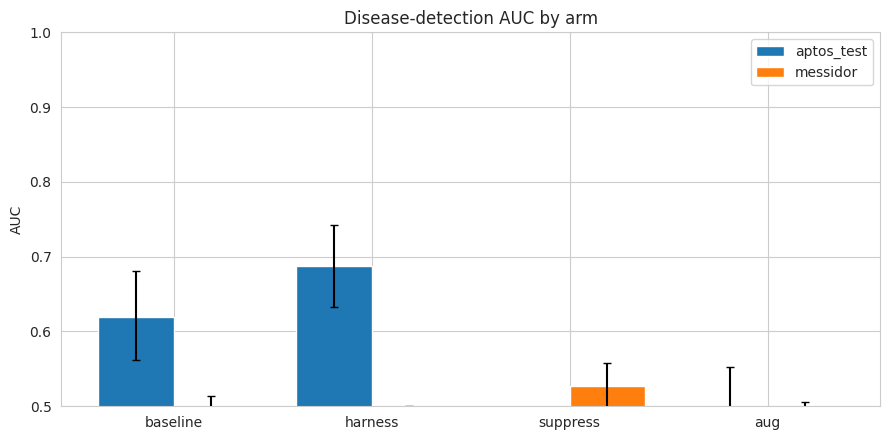

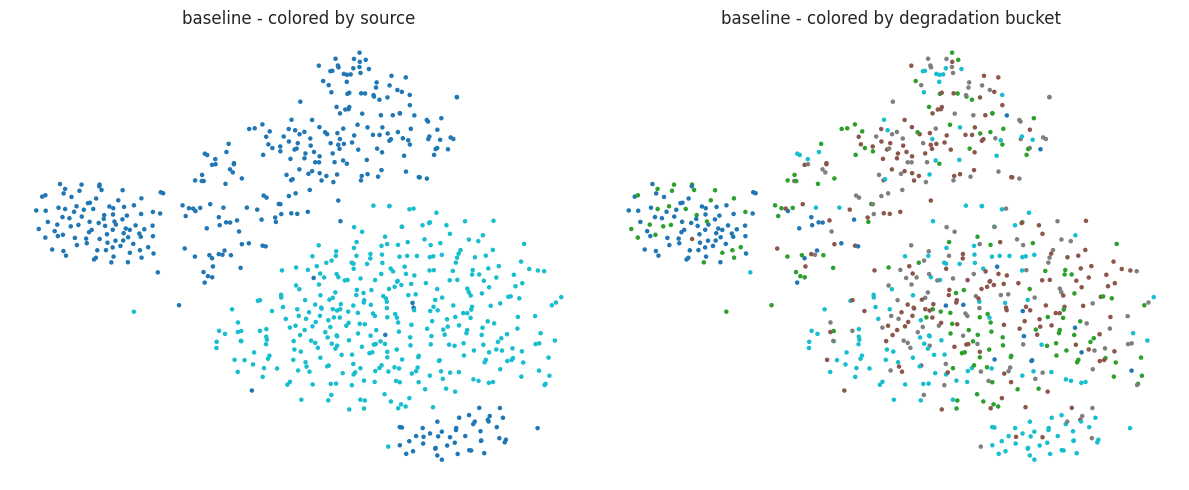

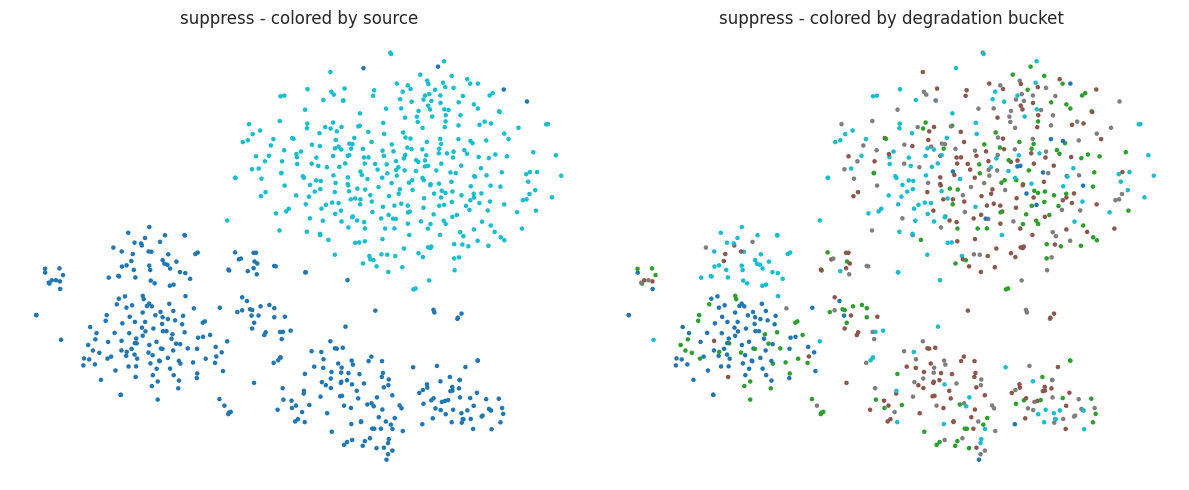

ALL DONE - download /kaggle/working/results/* and /kaggle/working/features/*.csv


In [7]:
def boot_auc(y, p, n=2000, seed=1):
    rng = np.random.default_rng(seed)
    y = np.asarray(y); p = np.asarray(p)
    aucs = []
    for _ in range(n):
        idx = rng.integers(0, len(y), len(y))
        if len(np.unique(y[idx])) < 2:
            continue
        aucs.append(roc_auc_score(y[idx], p[idx]))
    return float(np.percentile(aucs, 2.5)), float(np.percentile(aucs, 97.5))

def ece(y, p, n_bins=10):
    y = np.asarray(y); p = np.asarray(p)
    edges = np.linspace(0, 1, n_bins + 1); e = 0.0
    for i in range(n_bins):
        m = (p > edges[i]) & (p <= edges[i + 1]) if i else (p <= edges[i + 1])
        if m.sum():
            e += m.mean() * abs(y[m].mean() - p[m].mean())
    return float(e)

@torch.no_grad()
def infer(mode, df):
    ds = FundusDS(df, eval_tf)
    ld = torch.utils.data.DataLoader(ds, batch_size=64, shuffle=False, num_workers=2)
    bb, fwd, extra, ph = make_model(mode)
    bb.load_state_dict(torch.load(f'{WORK}/ckpt/{mode}.pt', map_location=DEVICE))
    bb.eval(); ps, fs = [], []
    for img, y, deg, bkt in ld:
        with torch.autocast('cuda'):
            logits, f = fwd(img.to(DEVICE), deg.to(DEVICE).float())
        ps.append(logits.float().softmax(1)[:, 1].cpu()); fs.append(f.float().cpu())
    return torch.cat(ps).numpy(), torch.cat(fs).numpy()

te_feat = F[F.source == 'aptos_test'].reset_index(drop=True)
me_feat = F[F.source == 'messidor'].reset_index(drop=True)
assert len(te_feat) > 0 and len(me_feat) > 0, 'feature frames missing for test/messidor - re-run Section 2.'
results, feats_store = [], {}
for mode in ['baseline', 'harness', 'suppress', 'aug']:
    p_te, f_te = infer(mode, te_feat)
    p_me, f_me = infer(mode, me_feat)
    feats_store[mode] = (f_te, f_me)
    for tag, p, y in [('aptos_test', p_te, te.label.values), ('messidor', p_me, me.label.values)]:
        auc = roc_auc_score(y, p); lo, hi = boot_auc(y, p)
        results.append({'arm': mode, 'eval': tag, 'AUC': auc, 'CI_lo': lo, 'CI_hi': hi, 'ECE': ece(y, p), 'n': len(y)})
res = pd.DataFrame(results)
print(res.to_string(index=False, float_format=lambda v: f'{v:.3f}'))
res.to_csv(f'{WORK}/results/table2_main.csv', index=False)

terc_rows = []
me_f = F[F.source == 'messidor'].copy()
me_f['terc'] = pd.qcut(me_f['brisque'], 3, labels=['low', 'mid', 'high'])
for mode in ['baseline', 'harness', 'suppress', 'aug']:
    p_me, _ = infer(mode, me_feat)
    for t in ['low', 'mid', 'high']:
        m = (me_f['terc'].values == t)
        if m.sum() > 10 and me.label.values[m].sum() > 0 and me.label.values[m].sum() < m.sum():
            terc_rows.append({'arm': mode, 'quality_tercile': t,
                              'AUC': roc_auc_score(me.label.values[m], p_me[m]), 'n': int(m.sum())})
terc = pd.DataFrame(terc_rows)
print(terc.to_string(index=False, float_format=lambda v: f'{v:.3f}'))
terc.to_csv(f'{WORK}/results/table3_terciles.csv', index=False)

fr = []
for mode in ['baseline', 'harness', 'suppress', 'aug']:
    f_te, f_me = feats_store[mode]
    n_te = min(1000, len(f_te)); n_me = min(1000, len(f_me))
    Xd = np.vstack([f_te[:n_te], f_me[:n_me]]); yd = np.array([0] * n_te + [1] * n_me)
    dom_acc = accuracy_score(yd, MLPClassifier((128, 64), max_iter=300, random_state=SEED).fit(Xd, yd).predict(Xd))
    Xq = np.vstack([f_te, f_me]); bq = np.concatenate([te_feat.deg_bucket.values, me_feat.deg_bucket.values])
    deg_acc = accuracy_score(bq, MLPClassifier((128, 64), max_iter=300, random_state=SEED).fit(Xq, bq).predict(Xq))
    fr.append({'arm': mode, 'domain_probe_acc': dom_acc, 'degradation_probe_acc': deg_acc,
               'task_AUC_messidor': res[(res['arm'] == mode) & (res['eval'] == 'messidor')]['AUC'].iloc[0]})
fr = pd.DataFrame(fr)
print(fr.to_string(index=False, float_format=lambda v: f'{v:.3f}'))
fr.to_csv(f'{WORK}/results/table4_forensic_probes.csv', index=False)

fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(4); w = 0.38
for tag, off in [('aptos_test', -w / 2), ('messidor', w / 2)]:
    d = res[res['eval'] == tag].set_index('arm').loc[['baseline', 'harness', 'suppress', 'aug']]
    ax.bar(x + off, d.AUC, w, yerr=[d.AUC - d.CI_lo, d.CI_hi - d.AUC], capsize=3, label=tag)
ax.set_xticks(x); ax.set_xticklabels(['baseline', 'harness', 'suppress', 'aug'])
ax.set_ylim(0.5, 1.0); ax.set_ylabel('AUC'); ax.legend(); ax.set_title('Disease-detection AUC by arm')
plt.tight_layout(); plt.savefig(f'{WORK}/results/fig3_auc_arms.png', dpi=200); plt.show()

for mode in ['baseline', 'suppress']:
    try:
        f_te, f_me = feats_store[mode]
        rng = np.random.default_rng(0)
        n_sub = int(min(600, len(f_te), len(f_me)))
        if n_sub < 40:
            print(f'[t-SNE] skipped for {mode}: only {n_sub} samples available')
            continue
        idx_t = rng.choice(len(f_te), n_sub, replace=False)
        idx_m = rng.choice(len(f_me), n_sub, replace=False)
        X = np.vstack([f_te[idx_t], f_me[idx_m]])
        z = TSNE(n_components=2, perplexity=min(30, max(5, n_sub // 4)),
                 random_state=SEED, init='pca').fit_transform(X)
        src_c = np.array([0] * n_sub + [1] * n_sub)
        bkt = np.concatenate([te_feat.deg_bucket.values[idx_t], me_feat.deg_bucket.values[idx_m]])
        fig, axes = plt.subplots(1, 2, figsize=(12, 5))
        for ax, c, title in [(axes[0], src_c, 'source'), (axes[1], bkt, 'degradation bucket')]:
            ax.scatter(z[:, 0], z[:, 1], c=c, s=5, cmap='tab10')
            ax.set_title(f'{mode} - colored by {title}'); ax.axis('off')
        plt.tight_layout(); plt.savefig(f'{WORK}/results/fig4_tsne_{mode}.png', dpi=200); plt.show()
    except Exception as e:
        print(f'[t-SNE] failed for {mode}: {e} (non-fatal, continuing)')

print('ALL DONE - download /kaggle/working/results/* and /kaggle/working/features/*.csv')

## 7. Reading the results (for the paper)
- **Table 1 / Fig 2** = RQ1 biomarker evidence. The shuffle control must be ~0.5 — if not, features leak identity; stop and investigate.
- **Table 2** = main result: harness should help on APTOS (biomarker); suppress should narrow the ID→Messidor AUC drop.
- **Table 3** = does harness win specifically on low-quality Messidor images? (expected yes on fundus).
- **Table 4 / Fig 4** = forensics: suppress arm should show the lowest domain-probe accuracy. If suppress costs task AUC while removing domain signal → your "invariance trade-off" discussion point.
- **CXR arm (NIH ChestX-ray14 + VinDr):** add those datasets, then replicate sections 2–6 — the code is data-agnostic. The paired fundus/CXR contrast is the paper's decision-rule evidence.

**Smoke-test note:** the first run validates detection heuristics (watch Section 1's printout). Most likely failure point: Messidor-2's CSV column names. Expected T4 runtime: ~30–45 min total.